In [1]:
import scanpy as sc
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import scvelo as scv
import anndata as ad
import pickle as pkl
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.stats import binned_statistic_2d
from sklearn.neighbors import NearestNeighbors
import scipy.sparse as sp
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import TruncatedSVD

from sklearn.decomposition import PCA
import umap
from itertools import product

python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

In [34]:
velo_gene_df = pd.read_csv(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_gene_subset.csv", index_col=0, header=0)

# velo_genes = ['Adgrl2', 'Alox5ap', 'Anxa3', 'Baz1a', 'Cst7', 'Ctsg', 'Elane',
#        'Ermap', 'Etfb', 'Fcgr2b', 'Gclm', 'Gfi1b', 'Gpc1', 'Gpr171',
#        'Gsr', 'Gstm5', 'H3f3a', 'H3f3b', 'Hp', 'Ifngr1', 'Ifrd2', 'Kel',
#        'Klf1', 'Lman2', 'Lncpint', 'Ltb4r1', 'Ly6c2', 'Magi2', 'Mmrn1',
#        'Mpo', 'Ms4a3', 'Msrb1', 'Mt1', 'Nkg7', 'Plac8', 'Prkcsh',
#        'Prss57', 'Prtn3', 'Ptpn18', 'Rab4a', 'Rassf2', 'Rpl21', 'Rps13',
#        'Rps24', 'S100a8', 'Sdf2l1', 'Srgn', 'Ssr2', 'Supt3', 'Tanc2',
#        'Tfdp1', 'Tmsb4x', 'Tpk1', 'Tut7', 'Wwox']

velo_genes = velo_gene_df.index.tolist()
velo_gene_df = velo_gene_df.loc[velo_genes,:]

In [35]:
adata_atac = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_input_atac.h5ad")
adata_rna = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_input_rna.h5ad")

adata_rna.var["highly_variable"] = True
adata_atac.var["highly_variable"] = True

atac_df = pd.DataFrame(data=adata_atac.X, index=adata_atac.obs_names.values, columns=adata_atac.var_names.values)
rna_df = pd.DataFrame(data=adata_rna.X, index=adata_rna.obs_names.values, columns=adata_rna.var_names.values)

## kNN 50 Smoothing of Signals
To calculate chromatin potential, we first smoothed DORC scores (chromatin space) and corresponding gene expression (RNA space) over a k-nearest neighbor graph (k-NN, k=50), calculated using normalized ATAC topics from cisTopic.

In [36]:
def minmax_cols(df):
    mn, mx = df.min(axis=0), df.max(axis=0)
    rng = (mx - mn).replace(0, np.nan)   # constant columns would divide by zero
    return ((df - mn) / rng).fillna(0)

In [37]:
assert (adata_atac.obs_names == adata_rna.obs_names).all()

peaks = sc.read_h5ad(rf"{python_data_dir}\all_atac_peaks_corr.h5ad")[adata_atac.obs_names]
Xp = sp.csr_matrix(peaks.X, dtype=np.float32)
Xp = Xp[:, np.asarray((Xp > 0).sum(0)).ravel() >= 0.01 * Xp.shape[0]]

def run_lsi(X, n_comps=30, scale=1e4):
    tf = sp.diags(1 / np.maximum(np.asarray(X.sum(1)).ravel(), 1)) @ X
    idf = np.log1p(X.shape[0] / (1 + np.asarray((X > 0).sum(0)).ravel()))
    X_t = (tf @ sp.diags(idf)).tocsr()
    X_t.data = np.log1p(X_t.data * scale)
    return TruncatedSVD(n_components=n_comps, algorithm="arpack", random_state=0).fit_transform(X_t)

Z = run_lsi(Xp)
logd = np.log(np.maximum(np.asarray(Xp.sum(1)).ravel(), 1))
r_depth = np.array([np.corrcoef(Z[:, j], logd)[0, 1] for j in range(Z.shape[1])])
print(np.round(r_depth[:5], 2))
adata_atac.obsm["X_lsi"] = Z[:, np.abs(r_depth) < 0.5]
sc.pp.pca(adata_rna, n_comps=30)

def knn_smoother(emb, k=50):
    idx = NearestNeighbors(n_neighbors=k).fit(emb).kneighbors(emb, return_distance=False)
    n = emb.shape[0]
    return sp.csr_matrix((np.full(n * k, 1 / k), (np.repeat(np.arange(n), k), idx.ravel())), shape=(n, n))

def smoothed_profile(adata, genes, S, q=0.01):
    C = sp.csr_matrix(adata[:, genes].layers["counts"])
    depth = adata.obs["depth"].to_numpy(float)
    rate = (S @ C).toarray() / (S @ depth)[:, None]
    lo, hi = np.quantile(rate, [q, 1 - q], axis=0)
    rate = (np.clip(rate, lo, hi) - lo) / np.where(hi > lo, hi - lo, 1)
    return pd.DataFrame(rate, index=adata.obs_names, columns=genes)

atac_pc = adata_atac.obsm["X_lsi"]
rna_pc = adata_rna.obsm["X_pca"][:, :30]
GRAPH = "atac"   # "atac" = paper; "separate" = RNA over its own PCs
S_a = knn_smoother(atac_pc)
S_r = S_a if GRAPH == "atac" else knn_smoother(rna_pc)

atac_velo = smoothed_profile(adata_atac, velo_genes, S_a)
rna_velo = smoothed_profile(adata_rna, velo_genes, S_r)

[ 0.81  0.47  0.02  0.1  -0.01]


In [38]:
BALANCE_SIGNS = True
if BALANCE_SIGNS:
    g = velo_gene_df.loc[velo_genes].sort_values("t_rna")
    flip = g.index[g.groupby("rna_dir").cumcount() % 2 == 1]
    atac_velo.loc[:, flip] = 1 - atac_velo.loc[:, flip]
    rna_velo.loc[:, flip] = 1 - rna_velo.loc[:, flip]

In [39]:
adata_rna.obs["celltype"] = adata_rna.obs["predicted.id"].values

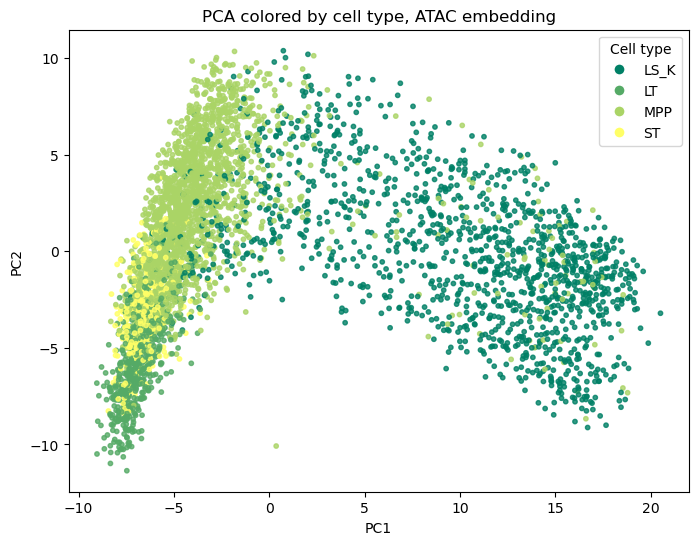

In [40]:
from matplotlib.lines import Line2D
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(["LT", "LS_K", "MPP", "ST"])
colors = le.transform(adata_rna.obs["celltype"].values)
cmap = plt.get_cmap("summer", len(le.classes_))

plt.figure(figsize=(8, 6))
plt.scatter(
    adata_atac.obsm["X_lsi"][:, 0],
    adata_atac.obsm["X_lsi"][:, 1],
    c=colors,
    cmap=cmap,
    s=10,
    alpha=0.8
)

# Create a legend
handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=cmap(i),
        markersize=8,
        label=celltype
    )
    for i, celltype in enumerate(le.classes_)
]

plt.legend(handles=handles, title="Cell type")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA colored by cell type, ATAC embedding")
plt.show()

## kNN 10 Assignment of ATAC to RNA
Find the 10 RNA profiles with the highest correlation to the current ATAC cell and compute their average as the predicted future state of the ATAC. The difference between the two points results in a velocity / chromatin potential.

Built together with Claude, to find a good compromise between the description in the paper and the implementation from SCARlink: https://github.com/snehamitra/SCARlink/blob/main/notebooks/chromatin_potential.ipynb; https://claude.ai/chat/68bcc85f-9655-47c8-801a-4c7dfbff5c9f

In [41]:
# ---- settings (paper values) ----
K_MATCH = 10          # cross-modal kNN
K_ARROW = 15          # arrow smoothing in low-dim space
USE_UMAP = True       # paper visualises on UMAP; set False to use ATAC PC1/PC2

A = atac_velo.to_numpy(float)   # smoothed, min-max scaled chromatin profiles (cells x genes)
R = rna_velo.to_numpy(float)    # smoothed, min-max scaled RNA profiles       (cells x genes)

def zrow(M):
    sd = M.std(1, keepdims=True)
    sd[sd == 0] = 1.0
    return (M - M.mean(1, keepdims=True)) / sd

# Central matching step!! 
# Pearson correlation of every ATAC profile i with every RNA profile j (over genes)
corr = zrow(A) @ zrow(R).T / A.shape[1]
nn = np.argpartition(-corr, K_MATCH - 1, axis=1)[:, :K_MATCH]   # top-10 RNA matches per ATAC cell

# chromatin-space embedding in which positions are averaged and arrows drawn
#atac_pc = adata_atac.obsm["X_pca"][:, :30]
atac_pc = adata_atac.obsm["X_lsi"]
E = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=0).fit_transform(atac_pc)

# arrow = mean position of matched cells - position of current cell in shared chromatin space
# The order here is not SUPER clear but: "We then calculated the distance (Di, j) between the Catac, i and the average of Crna, j in chromatin space"
arrows = E[nn].mean(axis=1) - E
arrows /= np.percentile(np.linalg.norm(arrows, axis=1), 99) # length normalisation

# smooth arrows over the 15 nearest neighbours in the low-dim space
idx = NearestNeighbors(n_neighbors=K_ARROW).fit(E).kneighbors(E, return_distance=False)
arrows_s = arrows[idx].mean(axis=1)

## Some Diagnostics 

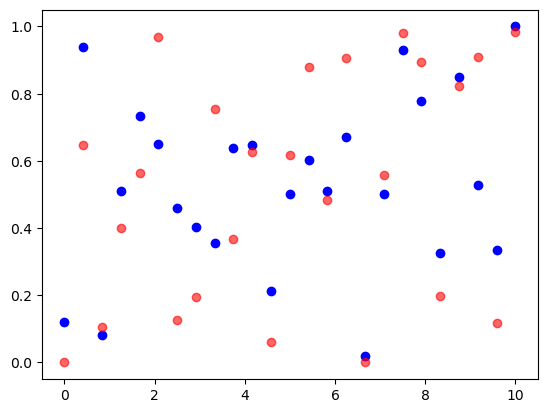

In [213]:
plt.scatter(np.linspace(0,10, len(velo_genes)), atac_velo.loc["AAACAGCCACTAAGTT",:], c="blue")
for i in range(1):
    plt.scatter(np.linspace(0,10, len(velo_genes)), rna_velo.iloc[nn[0,i],:], c="red", alpha=0.6)

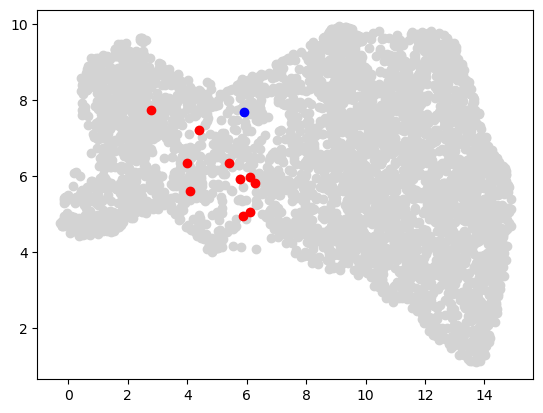

In [214]:
idx = 6

partners = E[nn[idx]]
point = E[idx]

plt.scatter(E[:,0], E[:,1], c="lightgrey")
plt.scatter(partners[:,0], partners[:,1], c="red")
plt.scatter(point[0], point[1], c="blue")

plt.show()

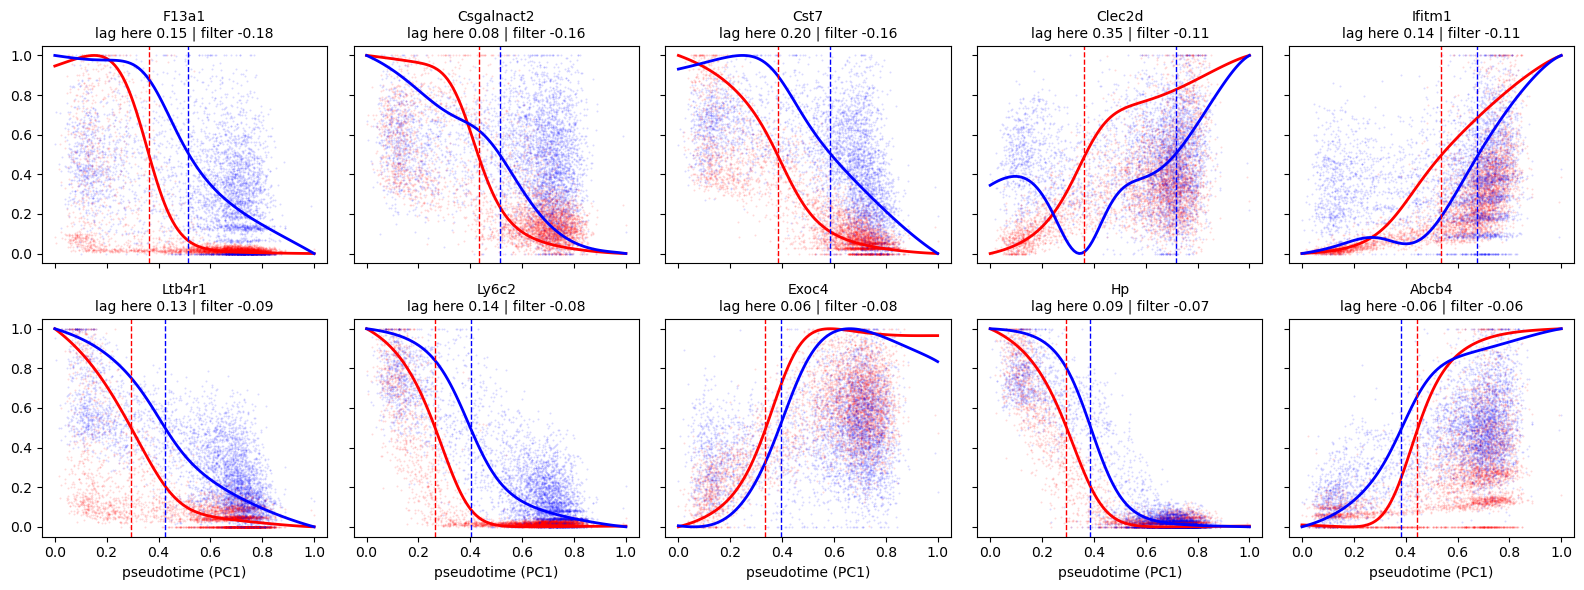

count    10.000000
mean      0.129293
std       0.105919
min      -0.060606
25%       0.083333
50%       0.136364
75%       0.148990
max       0.353535
dtype: float64


In [211]:
pt = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_input_rna.h5ad").obsm["X_pca"][:, 0]
t = (pt - pt.min()) / (pt.max() - pt.min())
grid = np.linspace(0, 1, 100)
W = np.exp(-0.5 * ((grid[:, None] - t[None, :]) / 0.1) ** 2)
W /= W.sum(1, keepdims=True)

def unflipped(P):
    P = P.copy()
    if BALANCE_SIGNS:
        P.loc[:, flip] = 1 - P.loc[:, flip]
    return P

def smooth_curves(P):
    c = W @ P.to_numpy(float)
    return (c - c.min(0)) / (c.max(0) - c.min(0))

genes = velo_gene_df.sort_values("lag").index[:10]
Pa, Pr = unflipped(atac_velo)[genes], unflipped(rna_velo)[genes]
Ca, Cr = smooth_curves(Pa), smooth_curves(Pr)
t_a = grid[np.argmin(np.abs(Ca - 0.5), axis=0)]
t_r = grid[np.argmin(np.abs(Cr - 0.5), axis=0)]

fig, axs = plt.subplots(2, 5, figsize=(16, 6), sharex=True, sharey=True)
for i, (ax, g) in enumerate(zip(axs.ravel(), genes)):
    ax.scatter(t, Pr[g], s=2, c="red", alpha=0.15, linewidths=0)
    ax.scatter(t, Pa[g], s=2, c="blue", alpha=0.15, linewidths=0)
    ax.plot(grid, Cr[:, i], c="red", lw=2)
    ax.plot(grid, Ca[:, i], c="blue", lw=2)
    ax.axvline(t_r[i], c="red", ls="--", lw=1)
    ax.axvline(t_a[i], c="blue", ls="--", lw=1)
    ax.set_title(f"{g}\nlag here {t_a[i] - t_r[i]:.2f} | filter {velo_gene_df.loc[g, 'lag']:.2f}", fontsize=10)
for ax in axs[-1]:
    ax.set_xlabel("pseudotime (PC1)")
plt.tight_layout()
plt.show()

lag_here = pd.Series(t_a - t_r, index=genes)
print(lag_here.describe())

In [215]:
# 1. Extract matrices for all cells (shape: n_cells x 10 genes)
atac_mat = Pa.to_numpy()
rna_mat = Pr.to_numpy()
n_cells = len(t)
n_genes = atac_mat.shape[1]

# 2. Z-score normalize across genes (axis=1) for efficient Pearson correlation
def zscore_normalize(mat):
    mean = np.mean(mat, axis=1, keepdims=True)
    std = np.std(mat, axis=1, keepdims=True)
    std[std == 0] = 1.0  # Prevent division by zero
    return (mat - mean) / std

atac_z = zscore_normalize(atac_mat)
rna_z = zscore_normalize(rna_mat)

# 3. Compute full cross-correlation matrix (n_cells ATAC x n_cells RNA)
# Note: If n_cells is extremely large (>40k), consider chunking this dot product.
corr_matrix = np.dot(atac_z, rna_z.T) / (n_genes - 1)

# 4. Per-Cell Analysis: Find the best matching RNA cell for every ATAC cell
best_rna_indices = np.argmax(corr_matrix, axis=1)
per_cell_pt_diff = t[best_rna_indices] - t

per_cell_results = pd.DataFrame({
    'atac_cell_idx': np.arange(n_cells),
    'pseudotime': t,
    'matched_rna_idx': best_rna_indices,
    'matched_rna_pt': t[best_rna_indices],
    'pt_difference': per_cell_pt_diff,
    'max_correlation': np.max(corr_matrix, axis=1)
})

print("=== Per-Cell Pseudotime Difference Summary ===")
print(per_cell_results['pt_difference'].describe())
print("\n")

# 5. Per-Velocity-Gene Analysis: Evaluate lag/shift per gene across all cells
gene_results = []
for i, g in enumerate(genes):
    # For each gene, compute correlation between ATAC and RNA expression vectors across all cells
    a_gene = atac_mat[:, i]
    r_gene = rna_mat[:, i]
    
    # Standardize 1D vectors
    a_norm = (a_gene - np.mean(a_gene)) / (np.std(a_gene) + 1e-8)
    r_norm = (r_gene - np.mean(r_gene)) / (np.std(r_gene) + 1e-8)
    
    # Find matching RNA cells or compute gene-specific pseudotime offset distribution
    # Here we look at the mean pseudotime difference for cells expressing high levels of gene g
    high_expr_mask = a_gene > np.percentile(a_gene, 75)
    
    # Mean pseudotime shift for this specific gene's active window
    gene_results.append({
        'gene': g,
        'mean_pt_diff_gene': np.mean(t[best_rna_indices[high_expr_mask]] - t[high_expr_mask]),
        'global_gene_lag': velo_gene_df.loc[g, 'lag']
    })

per_gene_df = pd.DataFrame(gene_results).set_index('gene')
print("=== Per-Velocity-Gene Pseudotime Summary ===")
print(per_gene_df)

=== Per-Cell Pseudotime Difference Summary ===
count    4238.000000
mean       -0.099302
std         0.150572
min        -0.568757
25%        -0.196069
50%        -0.079127
75%         0.005420
max         0.598595
Name: pt_difference, dtype: float64


=== Per-Velocity-Gene Pseudotime Summary ===
            mean_pt_diff_gene  global_gene_lag
gene                                          
F13a1               -0.156353        -0.181818
Csgalnact2          -0.098145        -0.161616
Cst7                -0.155668        -0.161616
Clec2d              -0.108344        -0.111111
Ifitm1              -0.034461        -0.111111
Ltb4r1              -0.103119        -0.090909
Ly6c2               -0.074597        -0.080808
Exoc4               -0.093152        -0.080808
Hp                  -0.070960        -0.070707
Abcb4               -0.073005        -0.060606


In [200]:
def local_grad(E, pt, k=30):
    idx = NearestNeighbors(n_neighbors=k).fit(E).kneighbors(E, return_distance=False)
    X = E[idx] - E[idx].mean(1, keepdims=True)
    y = pt[idx] - pt[idx].mean(1, keepdims=True)
    XtX = np.einsum("nki,nkj->nij", X, X) + 1e-6 * np.eye(2)
    return np.linalg.solve(XtX, np.einsum("nki,nk->ni", X, y)[..., None])[..., 0]

def cos_to_grad(a, g):
    return (a * g).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(g, axis=1) + 1e-12)

g = local_grad(E, pt)
rnd = np.random.default_rng(0).integers(0, len(pt), nn.shape)
res = pd.DataFrame({"observed": cos_to_grad(E[nn].mean(1) - E, g),
                    "random partners": cos_to_grad(E[rnd].mean(1) - E, g)})
print(res.mean())
print(res.groupby(pd.qcut(pt, 5, labels=False)).mean())

observed           0.270122
random partners    0.183744
dtype: float64
   observed  random partners
0  0.391402         0.503621
1  0.508110         0.464167
2  0.261226         0.083707
3  0.116044        -0.071902
4  0.073926        -0.060842


In [201]:
ct = adata_rna.obs["celltype"].values

order = ["LT", "ST", "MPP", "LS_K"]
a = E[nn].mean(1) - E
cent = {c: E[ct == c].mean(0) for c in order}
for c, nxt in zip(order[:-1], order[1:]):
    v, m = cent[nxt] - cent[c], a[ct == c].mean(0)
    print(f"{c} -> {nxt}: cos(mean arrow, centroid step) = {v @ m / (np.linalg.norm(v) * np.linalg.norm(m)):.2f}")
print(pd.Series(pt).groupby(ct).mean()[order])

LT -> ST: cos(mean arrow, centroid step) = -0.74
ST -> MPP: cos(mean arrow, centroid step) = -0.99
MPP -> LS_K: cos(mean arrow, centroid step) = -0.49
LT      6.724393
ST      5.396612
MPP     3.351768
LS_K   -7.544897
dtype: float32


Weirdly, even when I subset to exactly the genes where there is in fact a data driven lag, there is a super strong wrong direction across all cells.

## Continue computation

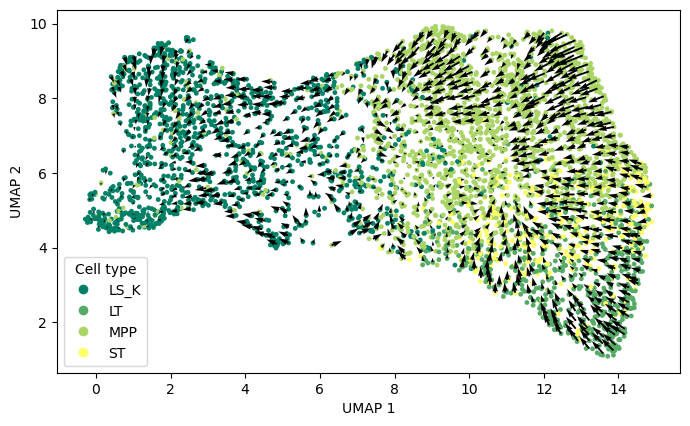

In [42]:
# Plotting of the resulting vectors in umap
N_BINS = 40
MIN_CELLS = 1          # drop sparse grid squares
ARROW_SCALE = 0.8      # >1 makes arrows longer for visibility

x, y = E[:, 0], E[:, 1]
u, v = arrows_s[:, 0], arrows_s[:, 1]

xe = np.linspace(x.min(), x.max(), N_BINS + 1)
ye = np.linspace(y.min(), y.max(), N_BINS + 1)

def bstat(vals, stat):
    return binned_statistic_2d(x, y, vals, stat, bins=[xe, ye]).statistic

cnt = bstat(None, "count")
X, Y = bstat(x, "mean"), bstat(y, "mean")      # arrow origin = mean cell position in the square
U, V = bstat(u, "mean"), bstat(v, "mean")      # average arrow of all cells in the square

keep = (cnt >= MIN_CELLS) & np.isfinite(U) & np.isfinite(V)
length = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(x, y, s=12, c=colors, cmap=cmap, alpha=1, linewidths=0, zorder=0)

q = ax.quiver(
    X[keep], Y[keep], U[keep] * ARROW_SCALE, V[keep] * ARROW_SCALE, #length[keep],
    angles="xy", scale_units="xy", scale=1,
    width=0.003, zorder=2, alpha=1, #cmap="inferno",
)

handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=cmap(i),
           markersize=8, label=celltype)
    for i, celltype in enumerate(le.classes_)
]
ax.legend(handles=handles, title="Cell type")

#plt.colorbar(q, ax=ax, shrink=0.4, label="chromatin potential (arrow length)")
ax.set_xlabel("UMAP 1" if USE_UMAP else "chromatin PC1")
ax.set_ylabel("UMAP 2" if USE_UMAP else "chromatin PC2")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

Curiously, when using E - E[avg] with the incorrect filtering of velocity genes by using a positive lag (RNA signal ahead of ATAC), results in the best results. This double mistake cancels out and gives quite good velocities. When using the branch method to find good velocity genes, or simply correcting the lag cutoff filter on the genes, the result is far more noisy and doesn't show the correct results... This might be related to the fact, that the positive lag genes show much larger lags and are more usable for the velocity computation.

When not filtering the genes at all by lag (as currently) the signal of the positive lag overpowers the other signal and it pretty much looks like the direction is just completely wrong...

One thing I am thinking about is not using only monotonically increasing and decreasing genes, but ones with a lag between the maxima or something similar. Just to get a stronger lag signal!!!